# 04. Comparison with equation-based global solvers

Established deterministic global solvers (SCIP, Couenne, BARON, LindoGlobal)
take an **algebraic model**: a list of variables, an objective and constraints
written in a modelling language such as Pyomo, GAMS or AMPL. jaxglobal takes a
**Python function**. This notebook puts the two side by side on the 21 test
problems of notebook 03:

1. how a JAX function is turned into a Pyomo model, and where that breaks;
2. whether every solver finds the certified optimum, and how fast.

The model-building code lives in `examples/compare.py`; this notebook imports
it, so the notebook and the command-line script cannot drift apart.

In [1]:
import json
import os
import pathlib
import sys

os.environ.setdefault("RUST_LOG", "warn")  # keep the local NLP solver's info messages out of the output
ROOT = pathlib.Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "examples"))

import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyomo.environ as pyo

import compare
from jaxglobal import minimize
from jaxglobal.problems import CONSTRAINED_PROBLEMS, PROBLEMS

INK, MUTED, BLUE, ORANGE, AQUA, YELLOW = "#1a1a19", "#77766f", "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "figure.dpi": 110})
P = {p.name: p for p in list(PROBLEMS) + list(CONSTRAINED_PROBLEMS)}

# Set to True to rerun all solvers on all problems (several minutes, needs
# SCIP, Couenne and a GAMS installation with BARON and LindoGlobal licences).
# By default the stored results in examples/compare_results.json are used.
RUN_SOLVERS = False

## From a JAX function to a Pyomo model

To give every solver exactly the same problem, the Pyomo models are not
written by hand. Instead the *same* Python function is evaluated on an array
of Pyomo variables, with the module `jnp` swapped for a small shim that maps
`jnp.sin`, `jnp.exp`, `jnp.sum`, … to their Pyomo counterparts. Python's
operator overloading then builds the expression tree:

In [2]:
print(inspect.getsource(compare.on_pyomo))
print("shim provides:", ", ".join(sorted(vars(compare.J))))

def on_pyomo(fn, X):
    """Evaluate a jnp-written function on a Pyomo variable array."""
    g = types.FunctionType(fn.__code__, {**fn.__globals__, "jnp": J}, fn.__name__, fn.__defaults__)
    return g(X)

shim provides: abs, arange, cos, exp, maximum, pi, sin, sqrt, stack, sum, tanh, where


For the six-hump camel function,

$$ f(a,b) = \left(4 - 2.1a^2 + \tfrac{a^4}{3}\right)a^2 + ab + (-4 + 4b^2)\,b^2, $$

this gives a model with two bounded variables and one objective expression:

In [3]:
m = compare.build(P["six_hump_camel"])
m.x.pprint()
print("objective:", m.obj.expr)

x : Size=2, Index={0, 1}
    Key : Lower : Value : Upper : Fixed : Stale : Domain
      0 :  -3.0 :   0.0 :   3.0 : False : False :  Reals
      1 :  -2.0 :   0.0 :   2.0 : False : False :  Reals
objective: (4 - 2.1*x[0]**2 + x[0]**4/3)*x[0]**2 + x[0]*x[1] + (-4 + 4*x[1]**2)*x[1]**2


This works whenever the function uses only operations that have an algebraic
counterpart. It fails for control flow. `piecewise_2d` contains
`jnp.where(a > 0.5, a - 0.5, 0.0)` and `jnp.maximum(a * b, -0.2)`, and the
shim has no way to translate them, because a modelling language has no
expression for "if":

In [4]:
print(inspect.getsource(P["piecewise_2d"].f))
try:
    compare.on_pyomo(P["piecewise_2d"].f, np.array([m.x[0], m.x[1]], dtype=object))
except compare._Unsupported as e:
    print("cannot translate:", e)

def piecewise(x):
    """Nonsmooth: jnp.where / max / abs on top of a nonconvex smooth part."""
    a, b = x[0], x[1]
    smooth = jnp.sin(3 * a) * jnp.cos(2 * b) + 0.1 * (a**2 + b**2)
    kink = jnp.where(a > 0.5, a - 0.5, 0.0) + jnp.abs(b + 0.3) * 0.5
    return smooth + kink + jnp.maximum(a * b, -0.2)

cannot translate: where


For the comparison we therefore wrote two reformulations by hand. The `where`
and `max` become the identity $\max(u, v) = \tfrac12\,(u + v + |u - v|)$, and
`tanh` in the neural network becomes $1 - 2/(e^{2z} + 1)$:

In [5]:
print(inspect.getsource(compare._max))
print(inspect.getsource(compare.piecewise_manual))

def _max(u, v):
    return (u + v + abs(u - v)) / 2

def piecewise_manual(X):
    a, b = X[0], X[1]
    smooth = pyo.sin(3 * a) * pyo.cos(2 * b) + 0.1 * (a**2 + b**2)
    kink = _max(a - 0.5, 0.0) + abs(b + 0.3) * 0.5  # where(a>.5, a-.5, 0)
    return smooth + kink + _max(a * b, -0.2)



`jaxglobal.export` now does these rewrites automatically: `export.to_scip(P["piecewise_2d"].f, lo, hi)` rewrites the `max` as above and reformulates the `where` with a binary, and `tanh` becomes $1 - 2/(e^{2z} + 1)$; see `examples/export_scip.py`. The comparison below keeps the hand-written versions, so its stored numbers are unchanged.

These are small examples, but they are the general situation: every
conditional, table lookup, `min`/`max` or special function has to be rewritten
by the modeller, often with extra binary variables or with identities like the
one above, before an equation-based solver can see it. jaxglobal works on the
traced function directly, so `where`, `maximum` and `tanh` need no rewriting.

## One problem, two ways

With a model in hand, SCIP is one call. Here both solvers on the six-hump camel
function, using SCIP if it is installed:

In [6]:
p = P["six_hump_camel"]
camel = lambda x: p.f(x)  # a fresh function object, so the timing comparison below starts cold
r = minimize(camel, p.lo, p.hi)
print(f"jaxglobal: f = {r.fun:.8f}, L = {r.lower_bound:.8f}, status = {r.status}, {r.time:.2f} s")
if pyo.SolverFactory("scip").available(exception_flag=False):
    s = compare.run_pyomo(p, "scip")
    print(f"SCIP:      f = {s['fun']:.8f}, termination = {s['status']}, {s['time']:.2f} s")

jaxglobal: f = -1.03162845, L = -1.03162859, status = optimal, 4.76 s


SCIP:      f = -1.03162845, termination = other, 0.14 s


Both find the same minimum. SCIP's termination `other` is Pyomo's name for
SCIP's "gap limit reached", i.e. a successful solve to the requested gap.
SCIP is also far faster here, because this jaxglobal call includes compiling
the bounding kernels and the local solver for a function it has not seen
before; the next section separates the two.

## All solvers on all problems

Each solver gets a 60 s limit and a relative and absolute gap of $10^{-6}$.
SCIP and Couenne read `.nl` files written by Pyomo; BARON and LindoGlobal run
through GAMS. The time is wall time including model writing for the `.nl`
solvers, and the solver-reported time for GAMS (which excludes about 0.7 s
of GAMS start-up); jaxglobal's time is discussed below.

An answer counts as **solved** if its objective is within $10^{-4}(1+|f^*|)$ of
the literature value $f^*$ (or of jaxglobal's certified value where there is no
literature value). We judge by value rather than by the reported termination
status, because some solvers report `locallyOptimal` or `other` for answers that
are in fact the global optimum.

In [7]:
RESULTS = ROOT / "examples" / "compare_results.json"
SOLVERS = ["jaxglobal", "jaxglobal_compiled", "scip", "couenne", "baron", "lindoglobal"]
EXTERNAL = ["scip", "couenne", "baron", "lindoglobal"]

if RUN_SOLVERS:
    rows = []
    for q in list(PROBLEMS) + list(CONSTRAINED_PROBLEMS):
        row = dict(name=q.name, n=int(q.lo.size), fstar=q.fstar, constrained=hasattr(q, "ineq"),
                   manual=q.name in compare.MANUAL, jaxglobal=compare.run_jax(q))
        for s in EXTERNAL:
            row[s] = compare.run_pyomo(q, s)
        rows.append(row)
    RESULTS.write_text(json.dumps(rows, indent=1))
rows = json.loads(RESULTS.read_text())
print(f"{len(rows)} problems, {sum(r['constrained'] for r in rows)} of them constrained")

21 problems, 7 of them constrained


jaxglobal needs no licences, so its column is always re-measured here, with the
current code. Each problem is solved twice in this process. The first call
traces and compiles the bounding kernels and the local solver for that function
(**cold**); the second reuses the compiled code (**compiled**). The cold time
compares directly with the other solvers, which also start from scratch on
every model. The compiled time is what a repeated solve of the same function
costs once compilation is out of the way: the search itself.

In [8]:
for row in rows:
    q = P[row["name"]]
    cold, warm = compare.run_jax(q), compare.run_jax(q)
    row["jaxglobal"], row["jaxglobal_compiled"] = cold, warm
RESULTS.write_text(json.dumps(rows, indent=1))
pd.DataFrame({"cold (s)": [r["jaxglobal"]["time"] for r in rows],
              "compiled (s)": [r["jaxglobal_compiled"]["time"] for r in rows],
              "nodes": [r["jaxglobal"]["nodes"] for r in rows]},
             index=[r["name"] for r in rows]).describe().loc[["min", "50%", "max"]].round(2)

,cold (s),compiled (s),nodes
min,1.98,0.01,3.0
50%,4.44,0.05,43.0
max,17.46,2.59,1445.0


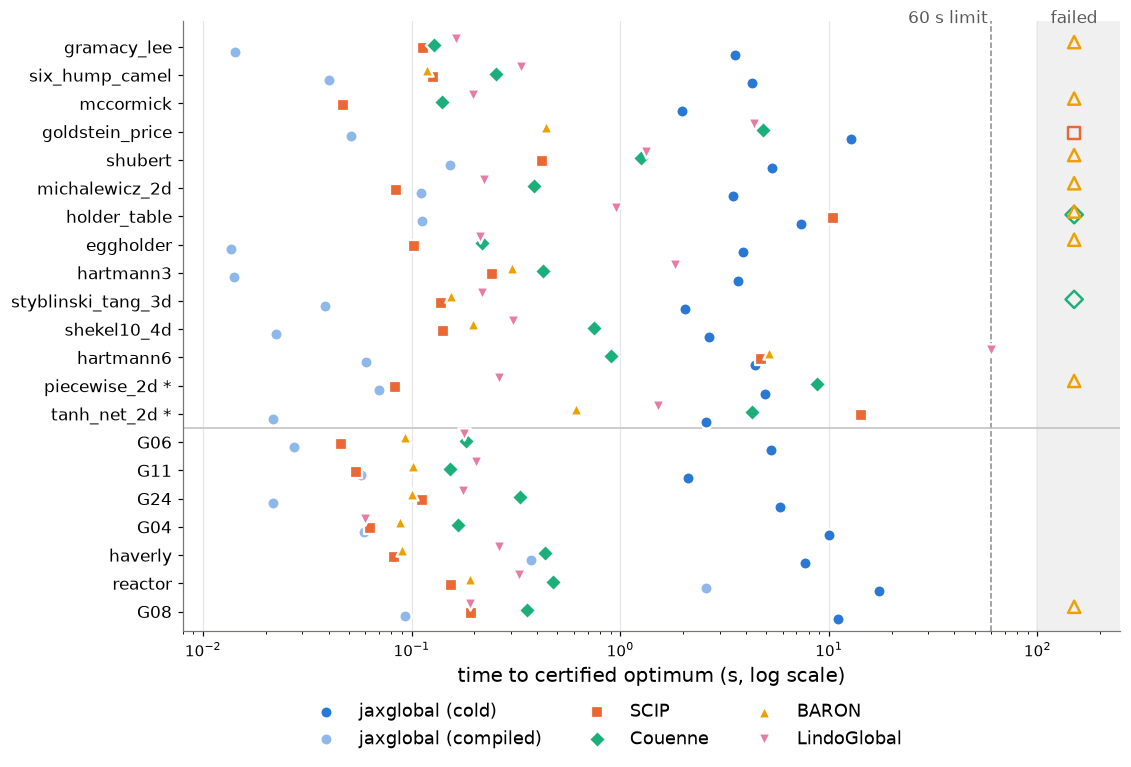

In [9]:
LABEL = {"jaxglobal": "jaxglobal (cold)", "jaxglobal_compiled": "jaxglobal (compiled)", "scip": "SCIP", "couenne": "Couenne", "baron": "BARON", "lindoglobal": "LindoGlobal"}
COLOR = {"jaxglobal": BLUE, "jaxglobal_compiled": "#8fb8ea", "scip": ORANGE, "couenne": AQUA, "baron": YELLOW, "lindoglobal": "#e87ba4"}
MARKER = {"jaxglobal": "o", "jaxglobal_compiled": "o", "scip": "s", "couenne": "D", "baron": "^", "lindoglobal": "v"}


def classify(row, s):
    """('solved', time) or (failure kind, None)."""
    r = row[s]
    ref = row["fstar"] if row["fstar"] is not None else row["jaxglobal"]["fun"]
    st = r.get("status", "")
    if st.startswith("unsupported") or (s == "baron" and st == "noSolution"):
        return "unsupported", None
    if st in ("maxTimeLimit", "maxIterations", "max_iter"):
        return "time limit", None
    if r.get("fun") is None:
        return "no solution", None
    if abs(r["fun"] - ref) > 1e-4 * (1 + abs(ref)):
        return "wrong optimum", None
    return "solved", r.get("solver_time") or r["time"]


names = [r["name"] + (" *" if r["manual"] else "") for r in rows]
fig, ax = plt.subplots(figsize=(11, 7.2))
y = np.arange(len(rows))[::-1]
fail_x = 150
off = dict(zip(SOLVERS, np.linspace(-0.28, 0.28, len(SOLVERS))))
for s in SOLVERS:
    solved, failed = [], []
    for yi, row in zip(y, rows):
        kind, t = classify(row, s)
        (solved if kind == "solved" else failed).append((t if kind == "solved" else fail_x, yi + off[s]))
    if solved:
        ax.scatter(*zip(*solved), s=64, marker=MARKER[s], color=COLOR[s], edgecolor="white", linewidth=1.5,
                   label=LABEL[s], zorder=3)
    if failed:
        ax.scatter(*zip(*failed), s=64, marker=MARKER[s], facecolor="none", edgecolor=COLOR[s], linewidth=1.6, zorder=3)
ax.axvline(60, color="0.55", lw=1, ls="--")
ax.text(58, len(rows) - 0.3, "60 s limit", color="0.35", fontsize=11, va="bottom", ha="right")
ax.axvspan(100, 250, color="0.94", zorder=0)
ax.text(150, len(rows) - 0.3, "failed", ha="center", color="0.35", fontsize=11, va="bottom")
ax.set_xscale("log"); ax.set_xlim(0.008, 250)
ax.set_yticks(y, names, fontsize=11); ax.set_ylim(-0.7, len(rows) - 0.1)
n_unc = sum(not r["constrained"] for r in rows)
ax.axhline(y[n_unc - 1] - 0.5, color="0.75", lw=1)
ax.set_xlabel("time to certified optimum (s, log scale)", fontsize=13)
ax.grid(axis="x", color="0.9", lw=0.8)
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.45, -0.09), frameon=False, fontsize=12)
fig.savefig(ROOT / "figures" / "benchmark.png", dpi=150, bbox_inches="tight")

Filled markers are solved problems, open markers in the grey band are
failures. Problems marked `*` needed a hand reformulation for the Pyomo
solvers; unconstrained problems are above the line, constrained below.

The same data as a summary:

In [10]:
summary = []
for s in SOLVERS:
    kinds = [classify(r, s) for r in rows]
    count = lambda k: sum(kk == k for kk, _ in kinds)  # noqa: E731
    summary.append({"solver": LABEL[s], "solved": f"{count('solved')}/{len(rows)}",
                    "unsupported": count("unsupported"), "time limit": count("time limit"),
                    "wrong / none": count("wrong optimum") + count("no solution"),
                    "median time, solved (s)": np.median([t for k, t in kinds if k == "solved"])})
pd.DataFrame(summary).set_index("solver").style.format({"median time, solved (s)": "{:.2f}"})

,solved,unsupported,time limit,wrong / none,"median time, solved (s)"
solver,,,,,
jaxglobal (cold),21/21,0,0,0,4.44
jaxglobal (compiled),21/21,0,0,0,0.05
SCIP,20/21,0,1,0,0.12
Couenne,19/21,0,1,1,0.39
BARON,13/21,8,0,0,0.15
LindoGlobal,21/21,0,0,0,0.26


In [11]:
fail = pd.DataFrame({LABEL[s]: [classify(r, s)[0] for r in rows] for s in SOLVERS}, index=[r["name"] for r in rows])
fail[(fail != "solved").any(axis=1)]

,jaxglobal (cold),jaxglobal (compiled),SCIP,Couenne,BARON,LindoGlobal
gramacy_lee,solved,solved,solved,solved,unsupported,solved
mccormick,solved,solved,solved,solved,unsupported,solved
goldstein_price,solved,solved,time limit,solved,solved,solved
shubert,solved,solved,solved,solved,unsupported,solved
michalewicz_2d,solved,solved,solved,solved,unsupported,solved
holder_table,solved,solved,solved,no solution,unsupported,solved
eggholder,solved,solved,solved,solved,unsupported,solved
styblinski_tang_3d,solved,solved,solved,time limit,solved,solved
piecewise_2d,solved,solved,solved,solved,unsupported,solved
G08,solved,solved,solved,solved,unsupported,solved


## What the comparison shows

* **Correctness.** jaxglobal and LindoGlobal solve all 21 problems. SCIP hits
  the time limit on Goldstein–Price, a degree-8 polynomial whose values run from
  3 to about $10^6$ on its box. Couenne hits its iteration limit on the 3-D
  Styblinski–Tang function and fails with an error on Holder table.
* **Coverage.** BARON does not accept trigonometric functions, so it rejects
  every problem containing `sin` or `cos` (8 of 21).
* **Speed.** From a cold start jaxglobal is the slowest solver here, with a
  median of about 4 s against 0.1–0.4 s for the others. Nearly all of that
  is tracing and XLA compilation of the bounding kernels and the local solver
  for a new function. Solved again with the compiled code, the median is
  below 0.1 s, and the slowest problem (the reactor network) takes under 3 s.
  For one-off solves of small problems, compile time is therefore the main
  cost to reduce.
* **Expressiveness.** jaxglobal takes the function as written, including
  `where`, `maximum` and `tanh`. The equation-based solvers needed two hand
  reformulations to see the same problems.
* LindoGlobal reaches the optimum on Hartmann-6 only at its 60 s limit
  (reported as `locallyOptimal`); it is counted as solved because the value is
  correct.

The SCIP, Couenne, BARON and LindoGlobal numbers come from the stored run in
`compare_results.json`; set `RUN_SOLVERS = True` above to regenerate them on
your machine. The jaxglobal numbers were measured when this notebook ran.